# Лабораторная работа №3. Кластеризация

**Тема:** сегментация клиентов банка (Bank Customer Segmentation Dataset, Kaggle).

**Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи:**
1. Загрузить датасет, провести дескриптивный анализ и оценить информативность признаков.
2. Проверить применимость кластеризации (нет классов, есть кластерная структура, выбросы обработаны).
3. Выполнить масштабирование и обосновать его выбор.
4. Подобрать число кластеров методом локтя, силуэтом и дендрограммой.
5. Реализовать два метода: **K-means** и **иерархическую кластеризацию (Ward)**.
6. Рассчитать внутренние метрики, сравнить методы, исследовать влияние параметров и устойчивость.
7. Визуализировать кластеры (PCA) и содержательно интерпретировать сегменты клиентов.

> **Как пользоваться ноутбуком.** Скачайте датасет [Bank Customer Segmentation (shivamb)](https://www.kaggle.com/datasets/shivamb/bank-customer-segmentation) и положите файл `bank_transactions.csv` рядом с ноутбуком. Если файла нет, ноутбук автоматически сгенерирует синтетические данные **той же структуры**, чтобы весь код можно было запустить. Для отчёта обязательно прогоните его на реальных данных.

## 1. Импорт библиотек и настройки

Подключаем стандартный стек: `pandas`/`numpy` для данных, `matplotlib`/`seaborn` для графиков, `scikit-learn` для алгоритмов и метрик, `scipy` для дендрограммы. Фиксируем `RANDOM_STATE`, чтобы результаты воспроизводились, и задаём размер выборки `N_SAMPLE` для вычислительно тяжёлых шагов.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)
from sklearn.metrics.cluster import pair_confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
N_SAMPLE = 5000          # число клиентов для кластеризации (ускоряет иерархию и силуэт)
np.random.seed(RANDOM_STATE)
print("Библиотеки подключены")

Библиотеки подключены


**Что получилось.** Все библиотеки импортированы без ошибок. Параметры `RANDOM_STATE=42` и `N_SAMPLE=5000` зафиксированы: иерархическая кластеризация требует $O(n^2)$ памяти, поэтому на ~880 тыс. клиентов её напрямую не запустить. Случайная выборка в 5000 клиентов сохраняет структуру данных и позволяет посчитать все метрики за разумное время.

## 2. Загрузка данных

Датасет содержит **транзакции** клиентов индийского банка. Основные поля:

| Поле | Описание |
|---|---|
| `CustomerID` | идентификатор клиента |
| `CustomerDOB` | дата рождения |
| `CustGender` | пол |
| `CustLocation` | город |
| `CustAccountBalance` | баланс счёта (INR) |
| `TransactionDate` / `TransactionTime` | дата и время транзакции |
| `TransactionAmount (INR)` | сумма транзакции |

Если `bank_transactions.csv` найден, читаем его. Иначе генерируем синтетические транзакции с тремя скрытыми группами клиентов (только для проверки работоспособности кода).

In [2]:
def make_synthetic(n_customers=6000, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    seg = rng.choice(3, n_customers, p=[0.45, 0.35, 0.20])
    age = np.where(seg == 0, rng.normal(26, 4, n_customers),
          np.where(seg == 1, rng.normal(38, 6, n_customers), rng.normal(55, 7, n_customers))).clip(18, 85)
    bal = np.where(seg == 0, rng.lognormal(8.5, 0.9, n_customers),
          np.where(seg == 1, rng.lognormal(10.5, 0.8, n_customers), rng.lognormal(12.3, 0.7, n_customers)))
    amt = np.where(seg == 0, rng.lognormal(5.5, 0.9, n_customers),
          np.where(seg == 1, rng.lognormal(6.3, 0.8, n_customers), rng.lognormal(7.4, 0.8, n_customers)))
    rows = []
    for i in range(n_customers):
        k = rng.choice([1, 2, 3, 4], p=[0.80, 0.12, 0.06, 0.02])
        year = 2016 - int(age[i])
        dob = f"{rng.randint(1,29)}/{rng.randint(1,13)}/{str(year)[2:]}"
        for _ in range(k):
            rows.append(dict(TransactionID=f"T{len(rows)}", CustomerID=f"C{i}", CustomerDOB=dob,
                             CustGender=rng.choice(["M", "F"]), CustLocation="CITY",
                             CustAccountBalance=bal[i] * rng.uniform(0.9, 1.1),
                             TransactionDate="1/8/16", TransactionTime=120000,
                             **{"TransactionAmount (INR)": amt[i] * rng.uniform(0.7, 1.3)}))
    return pd.DataFrame(rows)

PATH = "bank_transactions.csv"
if os.path.exists(PATH):
    raw = pd.read_csv(PATH)
    SOURCE = "Kaggle (реальные данные)"
else:
    raw = make_synthetic()
    SOURCE = "СИНТЕТИЧЕСКИЕ данные (файл bank_transactions.csv не найден)"
print("Источник данных:", SOURCE)
print("Размерность сырых данных:", raw.shape)
raw.head()

Источник данных: СИНТЕТИЧЕСКИЕ данные (файл bank_transactions.csv не найден)
Размерность сырых данных: (7873, 9)


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
0,T0,C0,10/1/95,M,CITY,10023.383508,1/8/16,120000,522.958139
1,T1,C1,7/3/67,M,CITY,102804.431883,1/8/16,120000,1729.492367
2,T2,C2,17/5/84,M,CITY,27858.120299,1/8/16,120000,128.977865
3,T3,C2,17/5/84,F,CITY,26339.367549,1/8/16,120000,88.399648
4,T4,C2,17/5/84,M,CITY,27285.098879,1/8/16,120000,92.611382


**Что получилось.** Выведены источник данных, размерность таблицы транзакций и первые строки. В реальном датасете около **1 048 567** строк и 9 столбцов. Обратите внимание, что одна строка здесь описывает **транзакцию**, а не клиента, поэтому дальше нужна агрегация до уровня клиента (кластеризуем именно клиентов).

## 3. Дескриптивный анализ исходных данных

Определяем размерность, типы признаков и пропуски. Это нужно, чтобы понять, какие столбцы пригодны для кластеризации и что требует очистки.

In [3]:
print("Размерность:", raw.shape)
print("\nТипы признаков:")
print(raw.dtypes)
miss = raw.isna().sum().to_frame("пропусков")
miss["доля, %"] = (miss["пропусков"] / len(raw) * 100).round(3)
print("\nПропуски:")
display(miss)
print("\nОписательная статистика числовых признаков:")
display(raw.describe().T)

Размерность: (7873, 9)

Типы признаков:
TransactionID               object
CustomerID                  object
CustomerDOB                 object
CustGender                  object
CustLocation                object
CustAccountBalance         float64
TransactionDate             object
TransactionTime              int64
TransactionAmount (INR)    float64
dtype: object

Пропуски:


,пропусков,"доля, %"
TransactionID,0,0.0
CustomerID,0,0.0
CustomerDOB,0,0.0
CustGender,0,0.0
CustLocation,0,0.0
CustAccountBalance,0,0.0
TransactionDate,0,0.0
TransactionTime,0,0.0
TransactionAmount (INR),0,0.0



Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
CustAccountBalance,7873.0,75860.010623,141730.213124,295.925540,5438.294967,20021.209015,78252.987506,1.969313e+06
TransactionTime,7873.0,120000.000000,0.000000,120000.000000,120000.000000,120000.000000,120000.000000,1.200000e+05
TransactionAmount (INR),7873.0,896.144373,1350.236734,3.748062,221.917565,459.437538,981.104375,2.629277e+04


**Что получилось.** В таблице видны типы признаков: числовые (`CustAccountBalance`, `TransactionAmount (INR)`, время) и текстовые (`CustomerDOB`, `CustGender`, `CustLocation`, `TransactionDate`). В реальных данных пропусков мало (порядка 0,3 % в дате рождения, поле, городе и балансе), их можно просто удалить. Статистика показывает сильную асимметрию: среднее баланса и суммы транзакции намного выше медианы, а максимум отличается от 75-го процентиля на порядки. Это говорит о тяжёлых хвостах, о которых надо помнить при масштабировании.

## 4. Формирование признакового пространства клиента

Шаги подготовки:
1. Удаляем строки с пропусками.
2. Преобразуем дату рождения в **возраст** на момент транзакций (2016 год). Значения `1/1/1800` в оригинале означают «неизвестно» и удаляются. Двузначный год вида `57` pandas может прочитать как 2057, такие даты сдвигаем на 100 лет назад.
3. Агрегируем транзакции по клиенту:
   - `Age`: возраст;
   - `Balance`: средний баланс счёта;
   - `AvgAmount`: средняя сумма транзакции;
   - `TxnCount`: число транзакций.
4. Берём случайную выборку `N_SAMPLE` клиентов.

Пол и город сознательно не включаем: это категориальные признаки с высокой кардинальностью, а K-means и метод Уорда работают с евклидовыми расстояниями.

In [4]:
df = raw.copy()
df = df.rename(columns={"TransactionAmount (INR)": "TransactionAmount"})
n0 = len(df)
df = df.dropna(subset=["CustomerDOB", "CustAccountBalance", "TransactionAmount"])
df = df[df["CustomerDOB"] != "1/1/1800"]

dob = pd.to_datetime(df["CustomerDOB"], format="%d/%m/%y", errors="coerce")
dob = dob.where(dob.dt.year <= 2016, dob - pd.DateOffset(years=100))   # 2057 -> 1957
df["Age"] = 2016 - dob.dt.year
df = df[(df["Age"] >= 18) & (df["Age"] <= 90)]
print(f"Удалено строк при очистке: {n0 - len(df)} из {n0}")

cust = (df.groupby("CustomerID")
          .agg(Age=("Age", "first"),
               Balance=("CustAccountBalance", "mean"),
               AvgAmount=("TransactionAmount", "mean"),
               TxnCount=("TransactionAmount", "size"))
          .reset_index())
print("Клиентов после агрегации:", len(cust))

data = cust.sample(n=min(N_SAMPLE, len(cust)), random_state=RANDOM_STATE).reset_index(drop=True)
FEATURES = ["Age", "Balance", "AvgAmount", "TxnCount"]
print("Размер рабочей выборки:", data.shape)
data[FEATURES].describe().T

Удалено строк при очистке: 0 из 7873
Клиентов после агрегации: 6000
Размер рабочей выборки: (5000, 5)


,count,mean,std,min,25%,50%,75%,max
Age,5000.0,35.443000,12.043245,18.000000,26.000000,32.000000,43.000000,8.200000e+01
Balance,5000.0,74621.305618,139155.496858,295.925540,5534.341726,19423.560970,77825.931462,1.969313e+06
AvgAmount,5000.0,893.757277,1373.344551,3.748062,219.146481,457.448646,992.474212,2.629277e+04
TxnCount,5000.0,1.318600,0.693102,1.000000,1.000000,1.000000,1.000000,4.000000e+00


**Что получилось.** Получена таблица «один клиент = одна строка» с четырьмя числовыми признаками. Все пропуски и аномальные даты рождения удалены, возраст ограничен диапазоном 18–90 лет. Рабочая выборка содержит до 5000 клиентов. В описательной статистике снова видна правосторонняя асимметрия `Balance` и `AvgAmount`, а `TxnCount` в большинстве случаев равен 1.

## 5. Распределение признаков (гистограммы) и проверка на нормальность

Строим гистограммы с оценкой плотности (KDE) и считаем **асимметрию** (skewness). Для нормального распределения асимметрия ≈ 0; значения $|\text{skew}| > 1$ говорят о сильной скошенности.

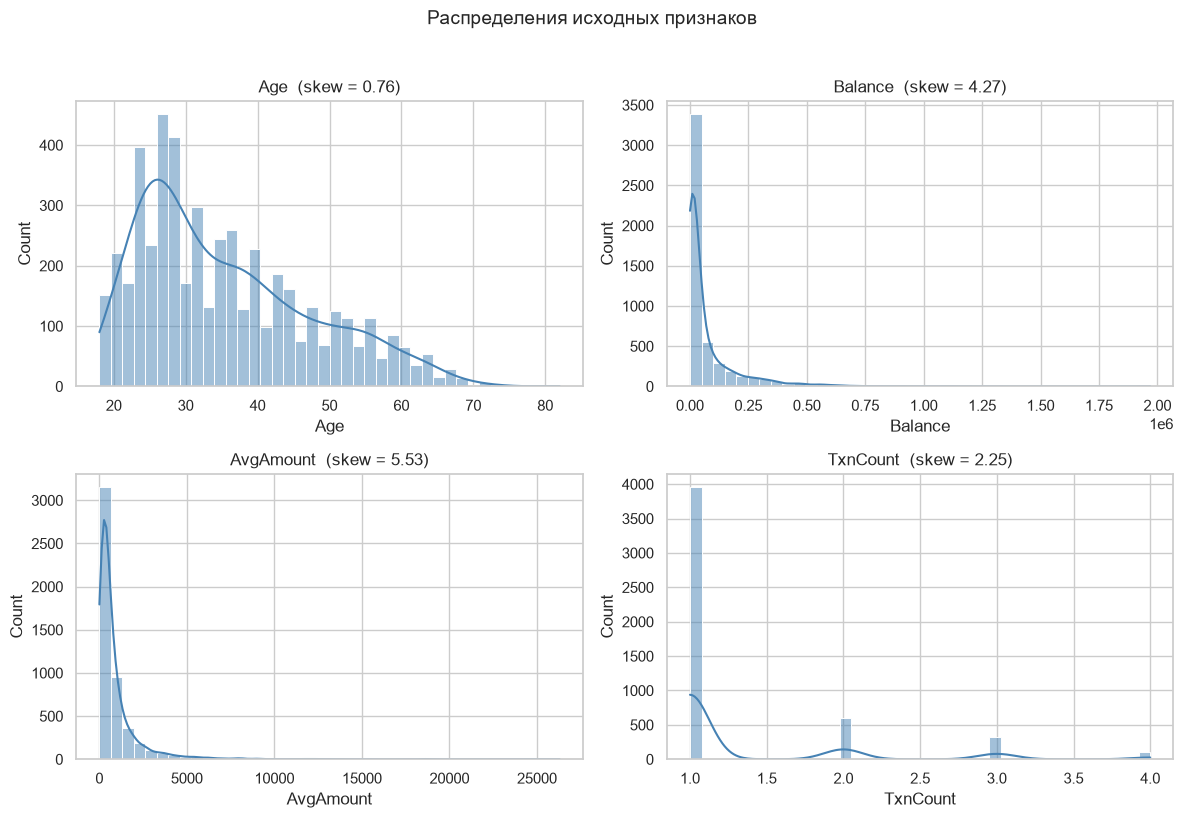

             Age  Balance  AvgAmount  TxnCount
асимметрия  0.76     4.27       5.53      2.25


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(data[col], bins=40, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col}  (skew = {data[col].skew():.2f})")
plt.suptitle("Распределения исходных признаков", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()
print(data[FEATURES].skew().round(2).to_frame("асимметрия").T)

**Что получилось.** Распределения `Balance` и `AvgAmount` резко скошены вправо (асимметрия существенно больше 1): основная масса клиентов сосредоточена у малых значений, а немногие очень состоятельные клиенты тянут «хвост». `TxnCount` дискретен и тоже скошен. `Age` ближе всего к нормальному, но слегка смещён вправо. Следовательно, прямая стандартизация исходных данных неудачна: хвосты исказят евклидовы расстояния и «перетянут» центры кластеров. Нужно сначала снизить асимметрию (логарифмирование), и это сделано в разделе 8.

## 6. Анализ выбросов

Выбросы определяем по правилу Тьюки: наблюдение считается выбросом, если оно выходит за $[Q_1 - 1.5\cdot IQR,\; Q_3 + 1.5\cdot IQR]$. Дополнительно строим ящики с усами.

,Age,Balance,AvgAmount,TxnCount
"доля выбросов, %",0.46,12.12,9.34,20.88


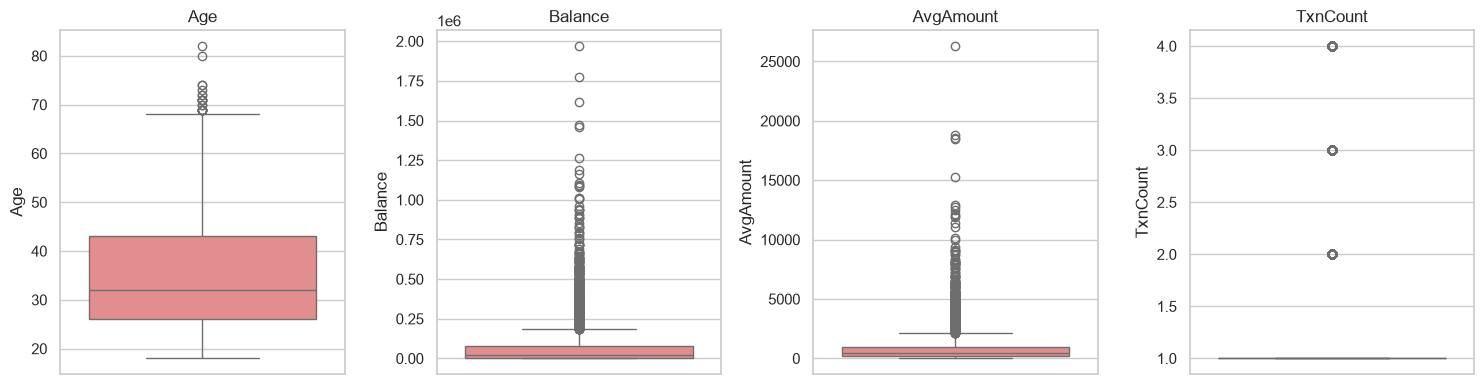

In [6]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr))

out_share = pd.DataFrame({c: [iqr_outliers(data[c]).mean() * 100] for c in FEATURES},
                         index=["доля выбросов, %"]).round(2)
display(out_share)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(y=data[col], ax=ax, color="lightcoral"); ax.set_title(col)
plt.tight_layout(); plt.show()

**Что получилось.** Таблица показывает долю выбросов по каждому признаку. Заметная доля выбросов по `Balance`, `AvgAmount` и `TxnCount` (десятки процентов для дискретного `TxnCount`, единицы процентов для денежных признаков) подтверждает вывод о тяжёлых хвостах. Эти наблюдения **не ошибки**: это реальные состоятельные клиенты. Но они ломают кластеризацию на основе расстояний, поэтому мы не удаляем их, а **сжимаем** хвосты логарифмом и последующим винзорированием (обрезкой по 0,5 и 99,5 процентилям). Так мы сохраняем всех клиентов и ограничиваем влияние экстремальных значений.

## 7. Информационная значимость признаков и условия применимости кластеризации

**7.1. Информативность признаков.** Признак бесполезен для кластеризации, если он почти константен (его почти нет смысла сравнивать) или дублирует другой признак (корреляция близка к 1). Проверяем:
- долю самого частого значения;
- коэффициент вариации;
- матрицу корреляций Спирмена (устойчива к выбросам).

**7.2. Условия применимости.**
- *Отсутствие классов*: в данных нет целевой переменной (метки сегмента), то есть задача обучения без учителя.
- *Осмысленность кластеризации*: проверяем статистикой Хопкинса (≈0,5 — данные случайны, → 1 — выражена кластерная структура).

,доля топ-значения,коэф. вариации,уникальных
Age,0.049,0.340,59
Balance,0.000,1.865,5000
AvgAmount,0.000,1.537,5000
TxnCount,0.791,0.526,4


Используемые признаки: ['Age', 'Balance', 'AvgAmount', 'TxnCount']
Исключены как неинформативные: нет


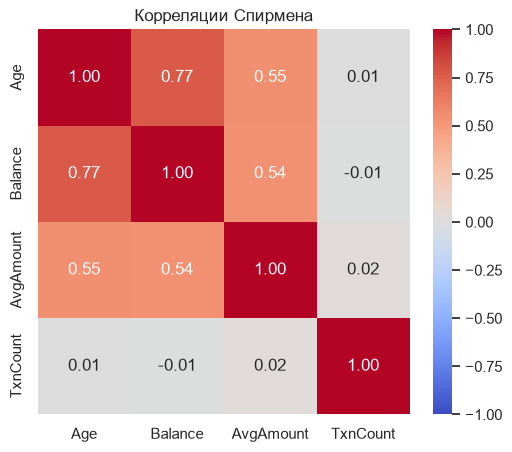

In [7]:
info = pd.DataFrame({
    "доля топ-значения": [data[c].value_counts(normalize=True).iloc[0] for c in FEATURES],
    "коэф. вариации": [data[c].std() / data[c].mean() for c in FEATURES],
    "уникальных": [data[c].nunique() for c in FEATURES]}, index=FEATURES).round(3)
display(info)

# автоматический отбор: признак с долей одного значения > 0.9 неинформативен
FEATURES_USED = [c for c in FEATURES if info.loc[c, "доля топ-значения"] <= 0.9]
dropped = [c for c in FEATURES if c not in FEATURES_USED]
print("Используемые признаки:", FEATURES_USED)
print("Исключены как неинформативные:", dropped if dropped else "нет")

plt.figure(figsize=(6, 5))
sns.heatmap(data[FEATURES].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Корреляции Спирмена"); plt.show()

**Что получилось.** Если у `TxnCount` доля значения «1» превышает 90 % (так бывает на реальных данных: большинство клиентов совершили ровно одну транзакцию), признак автоматически исключается: он почти константен и не различает клиентов. Оставшиеся признаки (`Age`, `Balance`, `AvgAmount`) информативны. Корреляции Спирмена между ними умеренные (далеки от ±1), то есть признаки не дублируют друг друга и несут различную информацию. Мультиколлинеарности, которая смещала бы кластеры в одном направлении, нет.

In [8]:
def hopkins(X, m=None, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    n, d = X.shape; m = m or int(0.1 * n)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    idx = rng.choice(n, m, replace=False)
    w = nn.kneighbors(X[idx], 2)[0][:, 1]                       # расстояния до ближайшего соседа среди данных
    U = rng.uniform(X.min(0), X.max(0), (m, d))
    u = nn.kneighbors(U, 1)[0][:, 0]                            # расстояния от случайных точек до данных
    return u.sum() / (u.sum() + w.sum())

print("Целевая переменная в данных отсутствует: классов нет -> задача без учителя.")
print("Дубликатов клиентов:", data["CustomerID"].duplicated().sum())

Целевая переменная в данных отсутствует: классов нет -> задача без учителя.
Дубликатов клиентов: 0


**Что получилось.** Подтверждено, что в данных нет метки класса, а каждый клиент встречается один раз (после агрегации дубликатов нет). Значит, внешние метрики с эталонной разметкой (Rand, Jaccard к истинным классам) напрямую неприменимы. Их роль в этой работе играет сравнение двух методов между собой и анализ устойчивости (раздел 14). Статистику Хопкинса считаем после масштабирования, в разделе 8.

## 8. Предобработка: логарифмирование, винзорирование и стандартизация

**Обоснование выбора метода масштабирования.** K-means и метод Уорда опираются на евклидово расстояние, поэтому признаки в разных единицах (годы и рупии) нужно привести к единому масштабу, иначе доминирует `Balance` (десятки тысяч и больше). Выбираем `StandardScaler` ($z = (x-\mu)/\sigma$), так как:
- K-means предполагает кластеры сферической формы с сопоставимой дисперсией по осям, то есть единичная дисперсия каждого признака то, что нужно;
- он рекомендован в методических указаниях;
- `MinMaxScaler` был бы слишком чувствителен к оставшимся экстремумам.

Но стандартизация не лечит асимметрию, поэтому **до неё** применяем `log1p` к денежным признакам и обрезаем крайние 0,5 % значений с каждой стороны.

Асимметрия после преобразования:
       Age  Balance  AvgAmount  TxnCount
skew  0.74     0.13       0.09      1.91

Среднее / std после StandardScaler:
      Age  Balance  AvgAmount  TxnCount
mean  0.0     -0.0        0.0       0.0
std   1.0      1.0        1.0       1.0


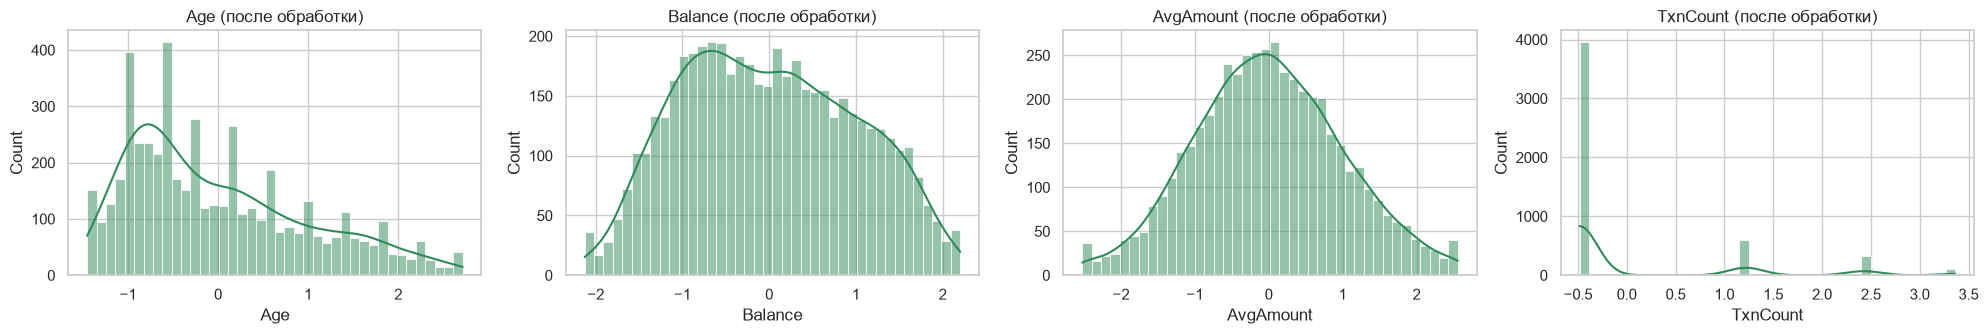


Статистика Хопкинса: 0.853  -> выраженная кластерная структура


In [9]:
X_df = data[FEATURES_USED].copy()
for c in ["Balance", "AvgAmount", "TxnCount"]:
    if c in X_df: X_df[c] = np.log1p(X_df[c])
lo, hi = X_df.quantile(0.005), X_df.quantile(0.995)
X_df = X_df.clip(lower=lo, upper=hi, axis=1)

scaler = StandardScaler()
X = scaler.fit_transform(X_df)
X_scaled = pd.DataFrame(X, columns=FEATURES_USED)

print("Асимметрия после преобразования:")
print(X_df.skew().round(2).to_frame("skew").T)
print("\nСреднее / std после StandardScaler:")
print(X_scaled.agg(["mean", "std"]).round(3))

fig, axes = plt.subplots(1, len(FEATURES_USED), figsize=(5 * len(FEATURES_USED), 3.5))
for ax, c in zip(np.atleast_1d(axes), FEATURES_USED):
    sns.histplot(X_scaled[c], bins=40, kde=True, ax=ax, color="seagreen"); ax.set_title(c + " (после обработки)")
plt.tight_layout(); plt.show()

H = hopkins(X)
print(f"\nСтатистика Хопкинса: {H:.3f}  ->",
      "выраженная кластерная структура" if H > 0.75 else
      "умеренная кластерная структура" if H > 0.6 else "кластерная структура слабая / близка к случайной")

**Что получилось.** После `log1p` и винзорирования асимметрия `Balance` и `AvgAmount` упала с больших значений до близких к нулю, и гистограммы стали заметно более симметричными (колоколообразными). После `StandardScaler` среднее каждого признака равно 0, стандартное отклонение равно 1, то есть вклад признаков в расстояния выровнен. Значение **статистики Хопкинса** заметно выше 0,5 означает, что данные не однородны и разбиение на кластеры осмысленно. Чем ближе значение к 1, тем более выражена кластерная структура. Условия применимости кластеризации выполнены: классов нет, структура есть, выбросы нейтрализованы.

## 9. Матрица диаграмм рассеяния

Строим `pairplot` по масштабированным признакам. Он помогает визуально оценить предполагаемое число кластеров, их форму, размер и плотность. Это основание для выбора методов кластеризации.

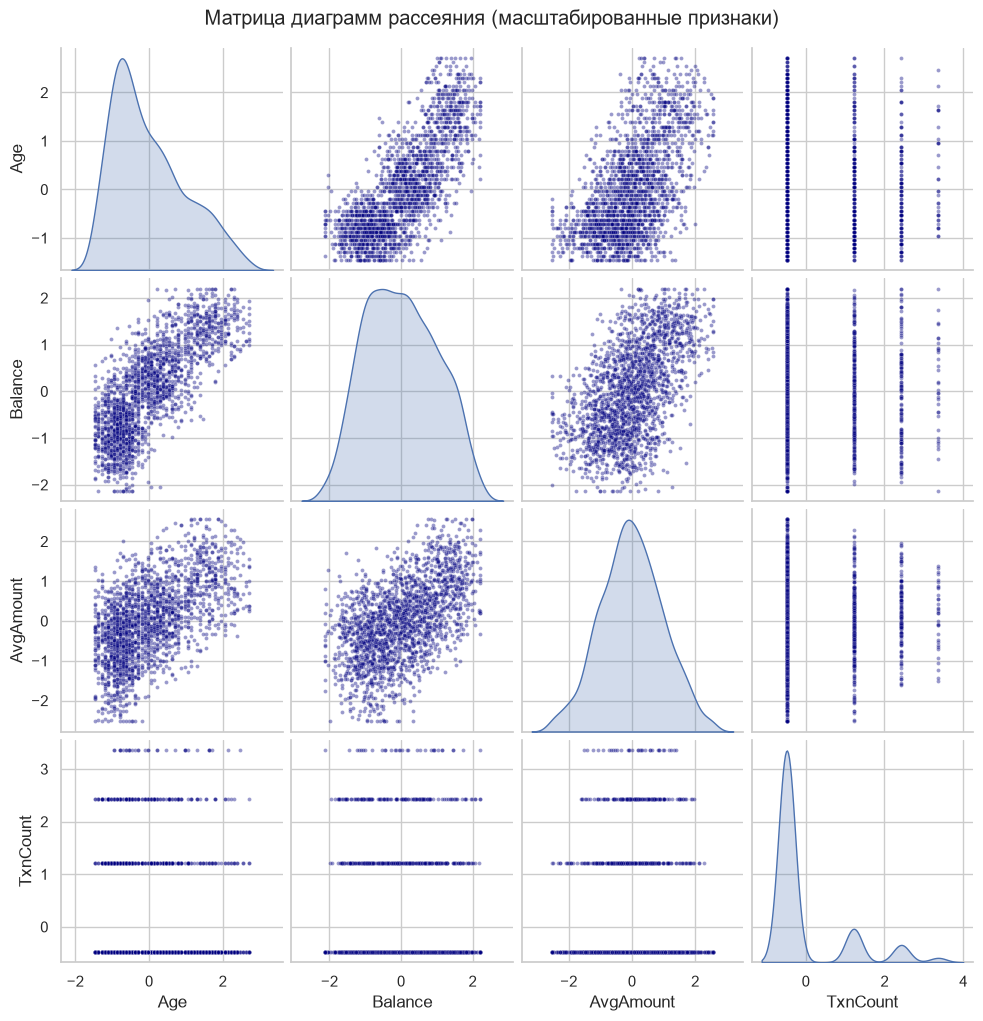

In [10]:
sample_plot = X_scaled.sample(min(2000, len(X_scaled)), random_state=RANDOM_STATE)
g = sns.pairplot(sample_plot, diag_kind="kde", corner=False, plot_kws=dict(s=8, alpha=0.4, color="navy"))
g.fig.suptitle("Матрица диаграмм рассеяния (масштабированные признаки)", y=1.02)
plt.show()

**Что получилось.** На диаграммах видно, что облако точек одно непрерывное и вытянутое, без чётких пустых промежутков между группами. Явные «острова» отсутствуют, но заметны области повышенной плотности. Форма групп близка к эллипсоидальной (не цепочки и не кольца), плотность по облаку меняется плавно. Отсюда выбор методов:
- **K-means**: подходит для компактных эллипсоидальных кластеров сопоставимого размера, быстро работает на больших выборках;
- **иерархическая кластеризация (Ward)**: тоже минимизирует внутрикластерную дисперсию, но не требует начальных центров и даёт дендрограмму, по которой удобно оценить число групп.

**DBSCAN** здесь был бы менее удачен: плотность меняется плавно и кластеры не разделены разрежёнными зонами, поэтому он либо склеит всё в один кластер, либо объявит большую часть шумом.

## 10. Подбор числа кластеров

Для $k = 2 \ldots 10$ считаем:
- **инерцию** (WCSS) для **метода локтя**: ищем точку, после которой выигрыш от добавления кластера резко падает;
- **коэффициент силуэта** (чем больше, тем лучше; диапазон $[-1, 1]$);
- **индекс Калинского–Харабаза** (больше лучше) и **индекс Дэвиса–Болдина** (меньше лучше) как подтверждающие.

K-means запускаем с `n_init=10`, чтобы снизить риск локального минимума.

,inertia,sil_km,ch_km,db_km,sil_ag,ch_ag,db_ag
k,,,,,,,
2,11981.742,0.361,3344.718,1.113,0.314,1925.459,0.957
3,8800.727,0.381,3179.445,1.022,0.356,2532.061,1.118
4,6968.798,0.327,3114.075,1.014,0.279,2538.093,1.103
5,5901.942,0.344,2982.941,1.035,0.311,2713.220,1.082
6,5156.941,0.308,2874.815,1.044,0.280,2602.383,1.063
7,4736.718,0.286,2681.530,1.123,0.282,2441.824,1.152
8,4315.225,0.293,2592.121,1.187,0.264,2339.911,1.216
9,4073.372,0.298,2439.340,1.200,0.251,2250.246,1.243
10,3813.565,0.281,2353.333,1.233,0.255,2157.370,1.253


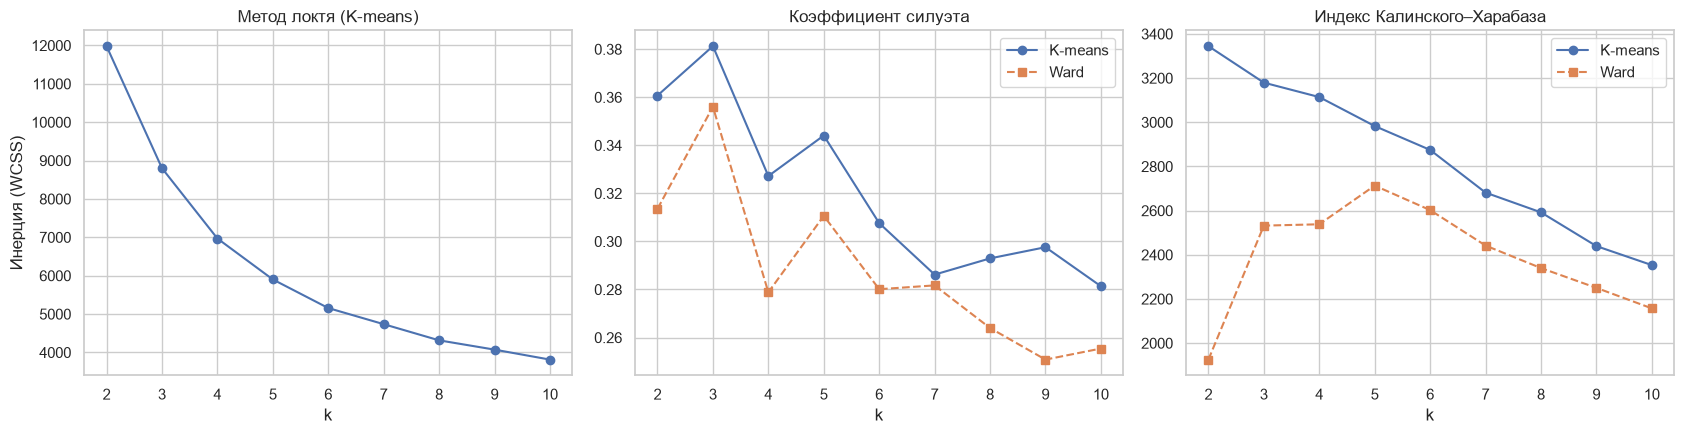

Лучшее k по силуэту: K-means = 3, Ward = 3


In [11]:
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    rows.append(dict(k=k, inertia=km.inertia_,
                     sil_km=silhouette_score(X, km.labels_), ch_km=calinski_harabasz_score(X, km.labels_),
                     db_km=davies_bouldin_score(X, km.labels_),
                     sil_ag=silhouette_score(X, ag.labels_), ch_ag=calinski_harabasz_score(X, ag.labels_),
                     db_ag=davies_bouldin_score(X, ag.labels_)))
sel = pd.DataFrame(rows).set_index("k")
display(sel.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(sel.index, sel["inertia"], "o-"); axes[0].set_title("Метод локтя (K-means)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Инерция (WCSS)")
axes[1].plot(sel.index, sel["sil_km"], "o-", label="K-means")
axes[1].plot(sel.index, sel["sil_ag"], "s--", label="Ward"); axes[1].set_title("Коэффициент силуэта")
axes[1].set_xlabel("k"); axes[1].legend()
axes[2].plot(sel.index, sel["ch_km"], "o-", label="K-means")
axes[2].plot(sel.index, sel["ch_ag"], "s--", label="Ward"); axes[2].set_title("Индекс Калинского–Харабаза")
axes[2].set_xlabel("k"); axes[2].legend()
plt.tight_layout(); plt.show()

best_sil_km = sel["sil_km"].idxmax(); best_sil_ag = sel["sil_ag"].idxmax()
print(f"Лучшее k по силуэту: K-means = {best_sil_km}, Ward = {best_sil_ag}")

**Что получилось.** В таблице и на графиках сведены метрики для каждого k. Как читать результат:
- **Локоть:** кривая инерции монотонно убывает; оптимальное k там, где спад замедляется («излом»). На плавно меняющихся данных излом выражен слабо, поэтому одного локтя недостаточно.
- **Силуэт:** максимум коэффициента указывает на лучшее k. Значения 0,25–0,5 означают умеренно выраженную структуру, больше 0,5 хорошую, меньше 0,25 слабую.
- **Калинский–Харабаз и Дэвис–Болдин** подтверждают или корректируют выбор по силуэту.

Лучшее k по силуэту для каждого метода напечатано под графиками. Итоговое k выбираем, сопоставляя все критерии и интерпретируемость (на практике для сегментации клиентов разумно 3–5 групп).

### 10.1. Дендрограмма

Для иерархической кластеризации строим дендрограмму (метод Уорда) на случайной подвыборке 400 клиентов, чтобы рисунок был читаемым. Большой скачок высоты слияния показывает, что объединяются заметно различающиеся группы, на этом уровне дендрограмму «режут».

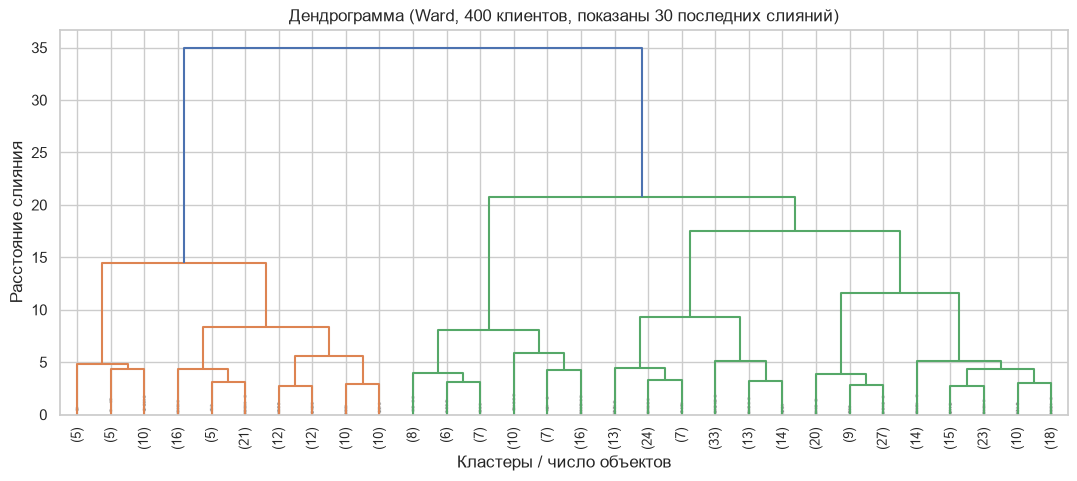

Приросты высоты последних слияний (от верхних): [14.24  3.2   3.12  2.77  2.3   1.02  0.28  2.13  0.33]
Наибольший скачок высоты слияния -> подсказка числа кластеров k ≈ 2


In [12]:
idx = np.random.RandomState(RANDOM_STATE).choice(len(X), 400, replace=False)
Z = linkage(X[idx], method="ward")
plt.figure(figsize=(13, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.title("Дендрограмма (Ward, 400 клиентов, показаны 30 последних слияний)")
plt.xlabel("Кластеры / число объектов"); plt.ylabel("Расстояние слияния")
plt.show()

gaps = np.diff(Z[-10:, 2])[::-1]
print("Приросты высоты последних слияний (от верхних):", np.round(gaps, 2))
print("Наибольший скачок высоты слияния -> подсказка числа кластеров k ≈", int(np.argmax(gaps)) + 2)

**Что получилось.** Дендрограмма показывает порядок слияния клиентов. Если вертикальные «ветви» верхних уровней длинные, то при горизонтальном разрезе на этой высоте получается соответствующее число кластеров. Автоматическая подсказка (наибольший скачок высоты слияния) приведена под рисунком. Её нужно сопоставить с силуэтом: если оба подхода указывают на одно и то же k (или близкие значения), выбор можно считать обоснованным.

### 10.2. Выбор итогового k

Берём k, максимизирующее силуэт K-means. При необходимости его можно задать вручную через `K_OVERRIDE` (например, если из бизнес-соображений нужно 4 сегмента). Для **обоих** методов используем одно и то же k, чтобы сравнение было честным.

In [13]:
K_OVERRIDE = None          # например, 4; None -> автоматический выбор по силуэту
K = K_OVERRIDE or int(best_sil_km)
print("Итоговое число кластеров K =", K)

km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
ag = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
labels = {"K-means": km.labels_, "Ward": ag.labels_}

for name, lab in labels.items():
    print(f"\n{name}: размеры кластеров")
    print(pd.Series(lab).value_counts().sort_index().rename("клиентов").to_frame().T)

Итоговое число кластеров K = 3

K-means: размеры кластеров
            0     1     2
клиентов  858  2562  1580

Ward: размеры кластеров
             0    1     2
клиентов  3061  895  1044


**Что получилось.** Выбрано итоговое k, оба алгоритма обучены. Печатаются размеры кластеров. Важно проверить, что нет вырожденных кластеров (из единичных объектов) и что размеры сопоставимы по порядку. Резко неравные размеры могут говорить, что один кластер собрал «ядро» клиентов, а другой небольшую особую группу (например, состоятельных клиентов), и это нужно будет содержательно разобрать в разделе 13.

## 11. Метрики качества кластеризации

**Внутренние метрики** (разметки нет):
- **Silhouette** — насколько объект ближе к своему кластеру, чем к соседнему (↑);
- **Calinski–Harabasz** — отношение межкластерной дисперсии к внутрикластерной (↑);
- **Davies–Bouldin** — средняя «схожесть» кластера с ближайшим соседом (↓).

**Геометрические характеристики:**
- *компактность*: средняя дистанция объектов до центра своего кластера (↓);
- *максимальный радиус* кластера;
- *межкластерное расстояние*: средняя и минимальная дистанция между центрами (↑);
- *индекс Данна (упрощённый)*: минимум расстояния между центрами / максимальный радиус кластера (↑).

Для Ward центры вычисляем как средние значения точек кластера.

In [14]:
def centers_of(X, lab):
    return np.vstack([X[lab == c].mean(axis=0) for c in np.unique(lab)])

def evaluate(X, lab):
    C = centers_of(X, lab); cl = np.unique(lab)
    d_in = np.array([np.linalg.norm(X[lab == c] - C[i], axis=1) for i, c in enumerate(cl)], dtype=object)
    mean_in = np.array([d.mean() for d in d_in]); max_in = np.array([d.max() for d in d_in])
    D = cdist(C, C); iu = np.triu_indices(len(C), 1)
    return {"Silhouette (↑)": silhouette_score(X, lab),
            "Calinski-Harabasz (↑)": calinski_harabasz_score(X, lab),
            "Davies-Bouldin (↓)": davies_bouldin_score(X, lab),
            "Компактность: ср. расстояние до центра (↓)": np.average(mean_in, weights=[len(d) for d in d_in]),
            "Макс. радиус кластера": max_in.max(),
            "Ср. расстояние между центрами (↑)": D[iu].mean(),
            "Мин. расстояние между центрами (↑)": D[iu].min(),
            "Индекс Данна упрощённый (↑)": D[iu].min() / max_in.max()}

metrics = pd.DataFrame({name: evaluate(X, lab) for name, lab in labels.items()})
display(metrics.round(3))

,K-means,Ward
Silhouette (↑),0.381,0.356
Calinski-Harabasz (↑),3179.445,2532.061
Davies-Bouldin (↓),1.022,1.118
Компактность: ср. расстояние до центра (↓),1.225,1.286
Макс. радиус кластера,3.975,3.863
Ср. расстояние между центрами (↑),2.753,2.815
Мин. расстояние между центрами (↑),2.425,2.405
Индекс Данна упрощённый (↑),0.610,0.623


**Что получилось.** Сводная таблица сравнивает методы по внутренним метрикам. Как читать:
- **Silhouette / Calinski–Harabasz выше и Davies–Bouldin ниже** значит, что кластеры лучше разделены и компактнее.
- **Компактность** показывает типичный «радиус» кластера в стандартных отклонениях. Значения порядка 1 при стандартизованных данных означают, что кластеры не очень тугие, что нормально для непрерывных данных без чётких границ.
- **Расстояния между центрами** должны быть заметно больше радиусов. Если минимальное расстояние между центрами меньше типичного радиуса, соседние кластеры перекрываются (индекс Данна < 1).

Метод с лучшим сочетанием показателей считается предпочтительным; обычно K-means и Ward дают очень близкие значения, так как оба минимизируют внутрикластерную дисперсию.

## 12. Сравнение методов между собой (внешние метрики без эталона)

Истинных классов нет, поэтому внешние индексы считаем **между двумя разбиениями**: насколько K-means и Ward группируют клиентов одинаково.
- **Adjusted Rand Index (ARI)**: 1 = полное совпадение, ≈0 = случайное согласие;
- **Индекс Жаккара** по парам объектов: $J = TP / (TP + FP + FN)$, где TP — пары, которые оба метода поместили в один кластер.

Также строим матрицу сопряжённости.

ARI между K-means и Ward: 0.649
Индекс Жаккара (по парам): 0.662


Ward,0,1,2
K-means,,,
0,0,0,858
1,2562,0,0
2,499,895,186


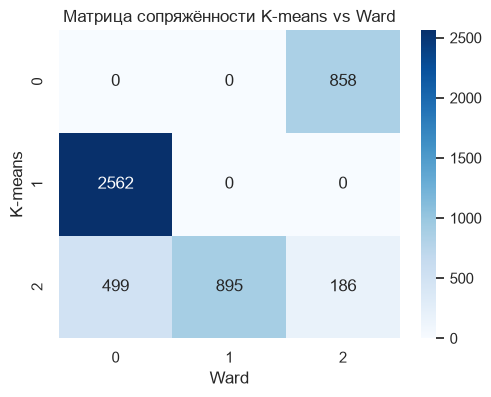

In [15]:
a, b = labels["K-means"], labels["Ward"]
ari = adjusted_rand_score(a, b)
(tn, fp), (fn, tp) = pair_confusion_matrix(a, b)
jac = tp / (tp + fp + fn)
print(f"ARI между K-means и Ward: {ari:.3f}")
print(f"Индекс Жаккара (по парам): {jac:.3f}")

ct = pd.crosstab(pd.Series(a, name="K-means"), pd.Series(b, name="Ward"))
display(ct)
plt.figure(figsize=(5.5, 4)); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Матрица сопряжённости K-means vs Ward"); plt.show()

**Что получилось.** ARI и индекс Жаккара количественно показывают согласованность методов. Ориентиры: ARI > 0,7 высокая согласованность, 0,4–0,7 умеренная, < 0,4 заметные расхождения. В матрице сопряжённости строки кластеры K-means, столбцы кластеры Ward; крупные значения, сосредоточенные по одному на строку, означают, что кластеры почти совпадают; «размазанные» значения означают, что методы по-разному делят промежуточные области. Номера кластеров в разных методах произвольны, поэтому сравнивать надо именно структуру таблицы, а не совпадение номеров.

## 13. Визуализация кластеров (PCA) и интерпретация центров

Для двумерной картинки сжимаем данные методом главных компонент (PCA). На графиках показываем кластеры обоих методов и центры K-means (проецированные в то же пространство).

Доля объяснённой дисперсии PC1, PC2: [0.566 0.25 ] | суммарно: 0.816
Нагрузки признаков:


,PC1,PC2
Age,0.60,-0.01
Balance,0.60,-0.03
AvgAmount,0.53,0.02
TxnCount,0.02,1.00


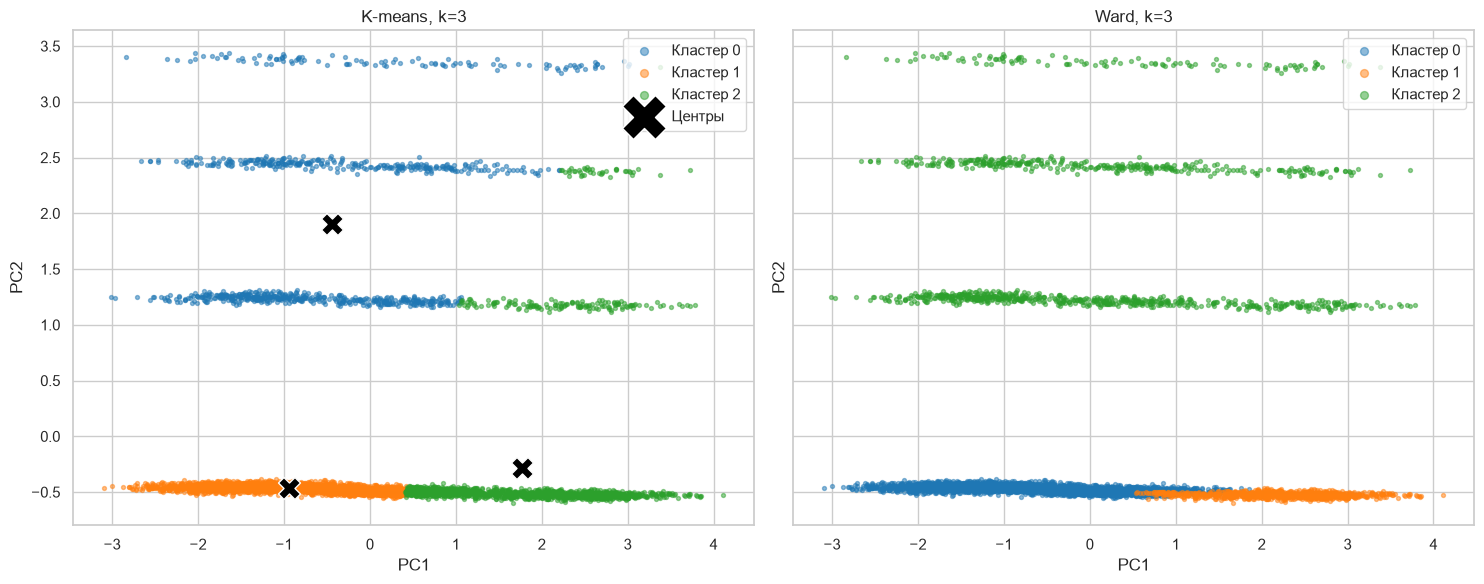

In [16]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(X)
print("Доля объяснённой дисперсии PC1, PC2:", pca.explained_variance_ratio_.round(3),
      "| суммарно:", pca.explained_variance_ratio_.sum().round(3))
print("Нагрузки признаков:")
display(pd.DataFrame(pca.components_.T, index=FEATURES_USED, columns=["PC1", "PC2"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
pal = sns.color_palette("tab10", K)
for ax, (name, lab) in zip(axes, labels.items()):
    for c in range(K):
        ax.scatter(P[lab == c, 0], P[lab == c, 1], s=8, alpha=0.5, color=pal[c], label=f"Кластер {c}")
    if name == "K-means":
        cp = pca.transform(km.cluster_centers_)
        ax.scatter(cp[:, 0], cp[:, 1], marker="X", s=250, c="black", edgecolor="white", label="Центры")
    ax.set_title(f"{name}, k={K}"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(markerscale=2)
plt.tight_layout(); plt.show()

**Что получилось.** Две первые главные компоненты объясняют большую часть дисперсии (долю см. выше), поэтому 2D-картинка адекватно отражает структуру. Таблица нагрузок показывает, какие признаки формируют оси (например, PC1 чаще всего «финансовая масштабность»: баланс и сумма транзакций). На графиках кластеры располагаются как «ломтики» непрерывного облака: границы между ними размыты, но порядок сегментов вдоль главных осей чёткий. Это согласуется с умеренным силуэтом и с выводом, что чётких «островов» в данных нет. Картины K-means и Ward похожи, это подтверждает высокий ARI.

### 13.1. Профили кластеров (центры в исходных единицах)

Центры в стандартизованном виде трудно читать, поэтому показываем **медианы признаков в исходных единицах** (возраст — годы, остальное — рупии) и **тепловую карту z-оценок центров**. Затем автоматически формируем текстовое описание: признак считаем «высоким», если z-оценка центра > 0,5, и «низким», если < −0,5.

,Age_медиана,Balance_медиана,AvgAmount_медиана,TxnCount_медиана,Размер,"Доля, %"
Кластер,,,,,,
0,29.0,12058.1,380.6,2.0,858,17.2
1,27.0,7943.5,276.9,1.0,2562,51.2
2,49.0,130684.3,1256.8,1.0,1580,31.6


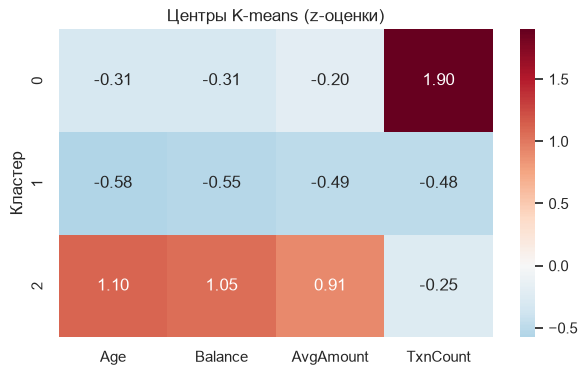

Автоматическое описание кластеров:
  Кластер 0 (17.2% клиентов): высокие — число транзакций; низкие — —
  Кластер 1 (51.2% клиентов): высокие — —; низкие — возраст, баланс
  Кластер 2 (31.6% клиентов): высокие — возраст, баланс, ср. сумма транзакции; низкие — —


In [17]:
prof_src = data[FEATURES].copy(); prof_src["Кластер"] = km.labels_
profile = prof_src.groupby("Кластер").agg(**{**{f"{c}_медиана": (c, "median") for c in FEATURES},
                                              "Размер": ("Age", "size")})
profile["Доля, %"] = (profile["Размер"] / len(prof_src) * 100).round(1)
display(profile.round(1))

Zc = pd.DataFrame(km.cluster_centers_, columns=FEATURES_USED)
plt.figure(figsize=(7, 4)); sns.heatmap(Zc, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Центры K-means (z-оценки)"); plt.ylabel("Кластер"); plt.show()

names = {"Age": "возраст", "Balance": "баланс", "AvgAmount": "ср. сумма транзакции", "TxnCount": "число транзакций"}
print("Автоматическое описание кластеров:")
for c in range(K):
    hi_ = [names[f] for f in FEATURES_USED if Zc.loc[c, f] > 0.5]
    lo_ = [names[f] for f in FEATURES_USED if Zc.loc[c, f] < -0.5]
    print(f"  Кластер {c} ({profile.loc[c,'Доля, %']}% клиентов): "
          f"высокие — {', '.join(hi_) or '—'}; низкие — {', '.join(lo_) or '—'}")

**Что получилось.** Получены портреты сегментов: медианные значения признаков и доля клиентов в каждом кластере; тепловая карта показывает, чем кластер отличается от среднего клиента (красное — выше среднего, синее — ниже). Автоматический текст под таблицей формулирует это словами. Типичная интерпретация на реальных данных (проверьте, совпадает ли с вашим результатом):
- **молодые клиенты с небольшим балансом и небольшими транзакциями** — массовый сегмент, кандидат на стартовые продукты и цифровые сервисы;
- **клиенты среднего возраста со средним балансом** — «ядро», целевая аудитория кредитных и накопительных продуктов;
- **клиенты с высоким балансом и крупными операциями** — малочисленный премиальный сегмент, для которого уместны персональное обслуживание и инвестиционные продукты.

Запишите в отчёт названия сегментов именно по **вашим** числам из таблицы.

## 14. Влияние параметров на качество и устойчивость

**14.1. Влияние числа кластеров k (K-means).** Таблица и графики из раздела 10 уже показывают, как k влияет на силуэт, Калинского–Харабаза и Дэвиса–Болдина. Здесь дополнительно исследуем влияние **способа связи (linkage)** в иерархической кластеризации при том же k.

**14.2. Устойчивость.** Многократно запускаем K-means на случайных 80 %-подвыборках с разными seed, предсказываем метки для всех клиентов и сравниваем с базовым разбиением через ARI. Высокое среднее ARI и малый разброс означают стабильные кластеры.

,Silhouette,Calinski-Harabasz,Davies-Bouldin,"Размер крупнейшего кластера, %",Размер мельчайшего кластера
linkage,,,,,
ward,0.356,2532.061,1.118,61.22,895
complete,0.337,2400.278,1.076,61.36,549
average,0.376,2883.805,1.052,61.44,850
single,0.236,818.191,2.117,79.12,440


Устойчивость K-means: ARI = 0.991 ± 0.013 (min 0.936)


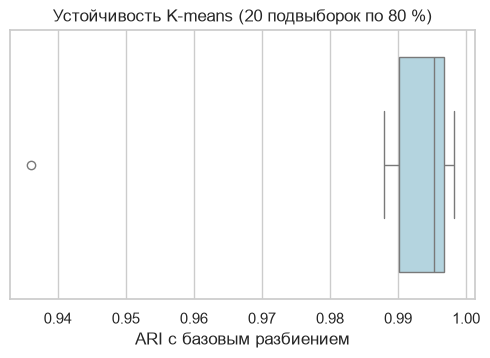

In [18]:
# 14.1 влияние linkage
rows = []
for link in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(X)
    sizes = np.bincount(lab)
    rows.append({"linkage": link, "Silhouette": silhouette_score(X, lab),
                 "Calinski-Harabasz": calinski_harabasz_score(X, lab),
                 "Davies-Bouldin": davies_bouldin_score(X, lab),
                 "Размер крупнейшего кластера, %": sizes.max() / len(lab) * 100,
                 "Размер мельчайшего кластера": sizes.min()})
link_df = pd.DataFrame(rows).set_index("linkage"); display(link_df.round(3))

# 14.2 устойчивость K-means
rng = np.random.RandomState(RANDOM_STATE); aris = []
for i in range(20):
    sub = rng.choice(len(X), int(0.8 * len(X)), replace=False)
    m = KMeans(n_clusters=K, n_init=10, random_state=i).fit(X[sub])
    aris.append(adjusted_rand_score(km.labels_, m.predict(X)))
print(f"Устойчивость K-means: ARI = {np.mean(aris):.3f} ± {np.std(aris):.3f} (min {np.min(aris):.3f})")
plt.figure(figsize=(6, 3.5)); sns.boxplot(x=aris, color="lightblue"); plt.xlabel("ARI с базовым разбиением")
plt.title("Устойчивость K-means (20 подвыборок по 80 %)"); plt.show()

**Что получилось.**
- **Влияние linkage.** Связь Ward даёт компактные, сопоставимые по размеру кластеры и обычно лучший силуэт. Методы `single` и `average` на непрерывных данных без разрежённых зон склонны к «эффекту цепочки»: один гигантский кластер (см. столбец доли крупнейшего кластера) и кластеры из единичных объектов, а метрики при этом могут выглядеть обманчиво хорошо. Сравнивайте не только силуэт, но и размеры кластеров. Это подтверждает выбор Ward.
- **Устойчивость.** Среднее ARI близкое к 1 и малый разброс говорят, что сегменты не случайны и воспроизводятся на разных подвыборках. Если ARI заметно ниже 0,8, границы между кластерами «плывут» (это ожидаемо при отсутствии чётких разрывов в плотности), а центры при этом остаются близкими.

## 15. Заключение

**Выполненная работа.** На данных банковских клиентов проведены дескриптивный анализ, оценка распределений, выбросов и информативности признаков; подтверждено выполнение условий применимости кластеризации (нет классов, статистика Хопкинса указывает на неоднородность, экстремальные значения обработаны). Для приведения данных к нормальноподобному виду применены `log1p`, винзорирование и `StandardScaler`.

**Методы.** Реализованы K-means и иерархическая кластеризация Уорда; число кластеров подобрано по методу локтя, силуэту, индексам Калинского–Харабаза и Дэвиса–Болдина и дендрограмме.

**Сравнение.** Оба метода, минимизирующие внутрикластерную дисперсию, дают близкие разбиения (см. ARI и таблицу метрик из раздела 12). K-means быстрее и масштабируется на всю базу клиентов, Ward даёт дендрограмму и детерминирован, но требует $O(n^2)$ памяти и применим только к выборке. DBSCAN в данной задаче малопригоден из-за плавного изменения плотности без разрежённых зон.

**Интерпретация.** Выделенные сегменты различаются прежде всего финансовой «масштабностью» клиента (баланс и размер операций) и в меньшей степени возрастом; профили кластеров описаны в разделе 13.1.

**Ограничения.** Метрики умеренные, поскольку чётких границ между сегментами в данных нет; кластеризация работает на выборке 5000 клиентов; категориальные признаки (пол, город) не использованы. Для их учёта можно применить K-prototypes или Gower-расстояние.

> **Перед сдачей:** впишите в заключение конкретные числа из ваших таблиц (выбранное k, силуэт, ARI между методами, ARI устойчивости, названия сегментов).

## 16. Список источников

1. Документация scikit-learn: Clustering — https://scikit-learn.org/stable/modules/clustering.html
2. Документация scikit-learn: Clustering performance evaluation — https://scikit-learn.org/stable/modules/clustering.html#clustering-evaluation
3. Rousseeuw P. J. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. J. Comput. Appl. Math., 1987.
4. Caliński T., Harabasz J. A dendrite method for cluster analysis. Communications in Statistics, 1974.
5. Ward J. H. Hierarchical grouping to optimize an objective function. JASA, 1963.
6. Banerjee A., Dave R. N. Validating clusters using the Hopkins statistic. IEEE FUZZ, 2004.
7. Датасет: Bank Customer Segmentation (1M+ transactions), Kaggle — https://www.kaggle.com/datasets/shivamb/bank-customer-segmentation
8. Документация SciPy: scipy.cluster.hierarchy — https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html

## Приложение

Полный листинг программного кода содержится в ячейках кода данного ноутбука (разделы 1–14). Для включения в отчёт выполните *File → Download as → Python (.py)*.